# Multi-model precipitation-type verification against mPING

End-to-end verification for:

- Aurora — EDNN
- Aurora — Bourgouin
- GraphCast — EDNN
- GraphCast — Bourgouin
- Pangu-Weather — EDNN
- Pangu-Weather — Bourgouin
- GFS — native GFS precipitation type
- GFS — EDNN

The workflow uses the same mPING QC and forecast-day design for all systems, then builds a **common-valid sample** for direct comparison.

## Main analyses

1. **Forecast skill:** CSI heatmaps as the primary summary; POD, FAR and frequency bias retained in tables/secondary heatmaps.
2. **Rain/snow reassignment:** for mPING-observed Ice Pellet and Freezing Rain, quantify the fraction subsequently diagnosed as Rain or Snow.
3. **EDNN uncertainty:** total predictive uncertainty (`aleatoric + epistemic`) for Aurora, GraphCast, Pangu-Weather and GFS, conditioned on the mPING-observed class. Epistemic and aleatoric components are retained for diagnosis.
4. **Attribution-oriented comparisons:** EDNN vs Bourgouin within the same AI-NWP and native GFS vs GFS-EDNN.

The +0 h initialization state is excluded. Day 1 uses +6/+12/+18/+24 h; Day 7 uses +150/+156/+162/+168 h.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

# ============================================================
# PATHS
# ============================================================

MPING_PATH = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"

AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
MODEL_DIRS = {
    "Aurora": AI_BASE / "au_ptype",
    "GraphCast": AI_BASE / "gc_ptype",
    "Pangu-Weather": AI_BASE / "pw_ptype",
    "GFS": Path("/glade/derecho/scratch/sakor/gfs/processed"),
}

OUT = AI_BASE / "verification_multimodel"
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ============================================================
# EXPERIMENT
# ============================================================

START = pd.Timestamp("2021-12-01 00:00:00")
END = pd.Timestamp("2022-04-01 00:00:00")  # exclusive
CONSENSUS = 70.0

LAT_MIN, LAT_MAX = 24.0, 50.0
LON_MIN, LON_MAX = -125.0, -66.0
MAX_DIST_KM = 30.0

PTYPE_COLS = {
    "sn_percent": "Snow",
    "ra_percent": "Rain",
    "pl_percent": "Ice Pellet",
    "fzra_percent": "Freezing Rain",
}

CLASS_NAMES = {0: "Rain", 1: "Snow", 2: "Ice Pellet", 3: "Freezing Rain"}
CLASS_CODES = {v: k for k, v in CLASS_NAMES.items()}
CLASS_ORDER = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]
FRZR_IP_CLASSES = ["Ice Pellet", "Freezing Rain"]

EPI_VARS = {
    "Rain": "ML_rain_epi", "Snow": "ML_snow_epi",
    "Ice Pellet": "ML_icep_epi", "Freezing Rain": "ML_frzr_epi",
}
ALE_VARS = {
    "Rain": "ML_rain_ale", "Snow": "ML_snow_ale",
    "Ice Pellet": "ML_icep_ale", "Freezing Rain": "ML_frzr_ale",
}

EXTRACT_VARS = [
    "ML_ptype",
    "ML_rain_ale", "ML_snow_ale", "ML_icep_ale", "ML_frzr_ale",
    "ML_rain_epi", "ML_snow_epi", "ML_icep_epi", "ML_frzr_epi",
    "BOURG_ptype", "GFS_ptype",
]


## 1. mPING QC and common Day 1–7 verification index


In [2]:
def prepare_mping(path):
    cols = ["datetime","lat","lon","report_count","sn_percent","ra_percent","pl_percent","fzra_percent"]
    d = pd.read_parquet(path, columns=cols)
    d["datetime"] = pd.to_datetime(d["datetime"])

    d = d[(d.datetime >= START) & (d.datetime < END)].copy()
    d = d[d.datetime.dt.hour.isin([0,6,12,18])].copy()
    d = d[d.lat.between(LAT_MIN,LAT_MAX) & d.lon.between(LON_MIN,LON_MAX)].copy()

    pcols = list(PTYPE_COLS)
    d["obs_class"] = d[pcols].idxmax(axis=1).map(PTYPE_COLS)
    d["obs_consensus"] = d[pcols].max(axis=1)
    if d.obs_consensus.max() <= 1:
        d["obs_consensus"] *= 100

    d = d[d.obs_consensus >= CONSENSUS].reset_index(drop=True)
    d["obs_id"] = np.arange(len(d), dtype=np.int64)
    return d[["obs_id","datetime","lat","lon","report_count","obs_class","obs_consensus"]]

def expand_forecast_days(obs):
    out = []
    for day in range(1,8):
        x = obs.copy()
        h = x.datetime.dt.hour
        x["forecast_day"] = day
        x["lead_hour"] = np.where(h == 0, 24*day, h + 24*(day-1)).astype(np.int16)
        x["init_time"] = x.datetime - pd.to_timedelta(x.lead_hour, unit="h")
        out.append(x)
    return pd.concat(out, ignore_index=True)

obs = prepare_mping(MPING_PATH)
master = expand_forecast_days(obs)

assert master.groupby("obs_id").size().eq(7).all()
assert not (master.lead_hour == 0).any()

print(f"mPING observations after >=70% QC: {len(obs):,}")
print(f"Expanded verification rows: {len(master):,}")
print("\nLead hours by forecast day:")
print(master.groupby("forecast_day").lead_hour.apply(lambda x: sorted(x.unique())))
print("\nObserved classes:")
print(obs.obs_class.value_counts().reindex(CLASS_ORDER))


mPING observations after >=70% QC: 29,834
Expanded verification rows: 208,838

Lead hours by forecast day:
forecast_day
1         [6, 12, 18, 24]
2        [30, 36, 42, 48]
3        [54, 60, 66, 72]
4        [78, 84, 90, 96]
5    [102, 108, 114, 120]
6    [126, 132, 138, 144]
7    [150, 156, 162, 168]
Name: lead_hour, dtype: object

Observed classes:
obs_class
Rain             11902
Snow             15894
Ice Pellet        1220
Freezing Rain      818
Name: count, dtype: int64


## 2. File discovery

The AI-NWP directories and GFS use per-initialization, per-lead NetCDF files. Rather than hard-coding every filename prefix, the resolver first tries the expected model prefix and then falls back to a unique `*_{lead:03d}.nc` file within the initialization directory.


In [3]:
FILE_PREFIX = {
    "Aurora": "aurora",
    "GraphCast": "graphcast",
    "Pangu-Weather": "pangu",
    "GFS": "gfs",
}

def init_string(t):
    return pd.Timestamp(t).strftime("%Y-%m-%dT00Z")

def resolve_file(model, init_time, lead_hour):
    s = init_string(init_time)
    folder = MODEL_DIRS[model] / s
    lead = f"{int(lead_hour):03d}"

    expected = folder / f"{FILE_PREFIX[model]}_{s}_{lead}.nc"
    if expected.exists():
        return expected

    hits = sorted(folder.glob(f"*_{lead}.nc"))
    if len(hits) == 1:
        return hits[0]
    if len(hits) == 0:
        return None

    raise RuntimeError(f"Ambiguous files for {model}, {s}, +{lead} h: {hits}")

# Quick file-coverage check before expensive collocation
required = master[["init_time","lead_hour"]].drop_duplicates().sort_values(["init_time","lead_hour"])
coverage = []

for model in MODEL_DIRS:
    for r in required.itertuples(index=False):
        p = resolve_file(model, r.init_time, r.lead_hour)
        coverage.append({
            "model": model, "init_time": r.init_time, "lead_hour": r.lead_hour,
            "exists": p is not None, "path": str(p) if p else None
        })

coverage = pd.DataFrame(coverage)
display(coverage.groupby("model").exists.agg(["sum","count"]))
print("\nMissing files by model:")
display(coverage[~coverage.exists].groupby("model").size())


,sum,count
model,,
Aurora,3325,3325
GFS,3325,3325
GraphCast,3325,3325
Pangu-Weather,3325,3325



Missing files by model:


Series([], dtype: int64)

## 3. Generic nearest-grid collocation


In [4]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1,lon1,lat2,lon2])
    dlat, dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

def extract_points(ds, group, model):
    q = ds.sel(
        latitude=xr.DataArray(group.lat.to_numpy(), dims="obs"),
        longitude=xr.DataArray(group.lon.to_numpy(), dims="obs"),
        method="nearest"
    )

    r = group.reset_index(drop=True).copy()
    r["model"] = model
    r["grid_lat"] = np.asarray(q.latitude).squeeze()
    r["grid_lon"] = np.asarray(q.longitude).squeeze()
    r["grid_distance_km"] = haversine(
        r.lat.to_numpy(), r.lon.to_numpy(),
        r.grid_lat.to_numpy(), r.grid_lon.to_numpy()
    )
    r["spatial_match_valid"] = r.grid_distance_km <= MAX_DIST_KM

    for var in EXTRACT_VARS:
        if var in q:
            r[var] = np.asarray(q[var]).squeeze()

    return r

def collocate_model(model, master):
    out = []
    groups = master.groupby(["init_time","lead_hour"], sort=True)
    n = len(groups)

    for i, ((init_time, lead_hour), g) in enumerate(groups, 1):
        path = resolve_file(model, init_time, lead_hour)
        if path is None:
            print(f"[MISSING] {model}: {init_string(init_time)} +{lead_hour:03d}")
            continue

        if i == 1 or i % 100 == 0 or i == n:
            print(f"{model}: {i}/{n} | {init_string(init_time)} +{lead_hour:03d} | N={len(g)}")

        with xr.open_dataset(path, decode_timedelta=False) as ds:
            out.append(extract_points(ds, g, model))

    if not out:
        raise RuntimeError(f"No files collocated for {model}")

    d = pd.concat(out, ignore_index=True)
    d.to_parquet(OUT / f"{model.lower().replace('-','_')}_mping_collocations.parquet", index=False)
    return d


In [5]:
collocated = {}

for model in ["Aurora", "GraphCast", "Pangu-Weather", "GFS"]:

    save_file = OUT / f"{model.lower().replace('-', '_')}_mping_collocations.parquet"

    if save_file.exists():
        print(f"Loading existing collocations: {model}")
        collocated[model] = pd.read_parquet(save_file)

    else:
        print(f"Generating collocations: {model}")
        collocated[model] = collocate_model(model, master)

    print(f"  {len(collocated[model]):,} rows")



Aurora
Aurora: 1/3325 | 2021-11-24T00Z +168 | N=8


/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


Aurora: 100/3325 | 2021-12-01T00Z +072 | N=2
Aurora: 200/3325 | 2021-12-05T00Z +024 | N=62
Aurora: 300/3325 | 2021-12-08T00Z +120 | N=18
Aurora: 400/3325 | 2021-12-12T00Z +048 | N=24
Aurora: 500/3325 | 2021-12-15T00Z +144 | N=6
Aurora: 600/3325 | 2021-12-19T00Z +072 | N=34
Aurora: 700/3325 | 2021-12-22T00Z +168 | N=102
Aurora: 800/3325 | 2021-12-26T00Z +096 | N=72
Aurora: 900/3325 | 2021-12-30T00Z +024 | N=106
Aurora: 1000/3325 | 2022-01-02T00Z +120 | N=102
Aurora: 1100/3325 | 2022-01-06T00Z +048 | N=24
Aurora: 1200/3325 | 2022-01-09T00Z +168 | N=74
Aurora: 1300/3325 | 2022-01-13T00Z +114 | N=122
Aurora: 1400/3325 | 2022-01-17T00Z +042 | N=46
Aurora: 1500/3325 | 2022-01-20T00Z +138 | N=44
Aurora: 1600/3325 | 2022-01-24T00Z +066 | N=22
Aurora: 1700/3325 | 2022-01-28T00Z +030 | N=186
Aurora: 1800/3325 | 2022-02-01T00Z +006 | N=8
Aurora: 1900/3325 | 2022-02-04T00Z +132 | N=10
Aurora: 2000/3325 | 2022-02-08T00Z +072 | N=52
Aurora: 2100/3325 | 2022-02-12T00Z +018 | N=84
Aurora: 2200/3325 | 

## 4. Collocation QC


In [6]:
qc_rows = []

for model, d in collocated.items():
    qc_rows.append({
        "Model": model,
        "Rows": len(d),
        "Median distance km": d.grid_distance_km.median(),
        "95th distance km": d.grid_distance_km.quantile(.95),
        "Max distance km": d.grid_distance_km.max(),
        ">30 km": (~d.spatial_match_valid).sum(),
        "ML invalid": (~d.ML_ptype.isin(CLASS_NAMES)).sum() if "ML_ptype" in d else np.nan,
        "Bourg invalid": (~d.BOURG_ptype.isin(CLASS_NAMES)).sum() if "BOURG_ptype" in d else np.nan,
        "GFS native invalid": (~d.GFS_ptype.isin(CLASS_NAMES)).sum() if "GFS_ptype" in d else np.nan,
    })

qc = pd.DataFrame(qc_rows)
display(qc.round(3))
qc.to_csv(OUT/"collocation_qc.csv", index=False)


,Model,Rows,Median distance km,95th distance km,Max distance km,>30 km,ML invalid,Bourg invalid,GFS native invalid
0,Aurora,208838,9.736,15.011,18.234,0,148,0,NaN
1,GraphCast,208838,9.736,15.011,18.234,0,758,0,NaN
2,Pangu-Weather,208838,9.736,15.011,18.234,0,1330,0,NaN
3,GFS,208838,9.736,15.011,18.234,0,0,0,98280.0


## 5. Convert to a unified diagnostic table

Only the requested eight forecast/diagnostic combinations are retained:

1. Aurora EDNN
2. Aurora Bourgouin
3. GraphCast EDNN
4. GraphCast Bourgouin
5. Pangu-Weather EDNN
6. Pangu-Weather Bourgouin
7. GFS Native
8. GFS EDNN

GFS Bourgouin is deliberately excluded.


In [7]:
SYSTEMS = [
    ("Aurora","EDNN","ML_ptype"),
    ("Aurora","Bourgouin","BOURG_ptype"),
    ("GraphCast","EDNN","ML_ptype"),
    ("GraphCast","Bourgouin","BOURG_ptype"),
    ("Pangu-Weather","EDNN","ML_ptype"),
    ("Pangu-Weather","Bourgouin","BOURG_ptype"),
    ("GFS","Native","GFS_ptype"),
    ("GFS","EDNN","ML_ptype"),
]

SYSTEM_ORDER = [
    "Aurora — EDNN",
    "Aurora — Bourgouin",
    "GraphCast — EDNN",
    "GraphCast — Bourgouin",
    "Pangu-Weather — EDNN",
    "Pangu-Weather — Bourgouin",
    "GFS — Native",
    "GFS — EDNN",
]

frames = []

for model, method, pred_col in SYSTEMS:
    d = collocated[model].copy()
    keep = [
        "obs_id","datetime","lat","lon","obs_class","obs_consensus",
        "forecast_day","lead_hour","init_time","grid_distance_km","spatial_match_valid",pred_col
    ]
    x = d[keep].copy()
    x = x.rename(columns={pred_col:"pred_code"})
    x["Model"] = model
    x["Method"] = method
    x["System"] = f"{model} — {method}"
    frames.append(x)

predictions = pd.concat(frames, ignore_index=True)
predictions["pred_valid"] = predictions.pred_code.isin(CLASS_NAMES)
predictions["obs_code"] = predictions.obs_class.map(CLASS_CODES).astype(int)

display(predictions.groupby("System").agg(
    rows=("obs_id","size"),
    spatial_valid=("spatial_match_valid","sum"),
    pred_valid=("pred_valid","sum")
).reindex(SYSTEM_ORDER))


,rows,spatial_valid,pred_valid
System,,,
Aurora — EDNN,208838,208838,208690
Aurora — Bourgouin,208838,208838,208838
GraphCast — EDNN,208838,208838,208080
GraphCast — Bourgouin,208838,208838,208838
Pangu-Weather — EDNN,208838,208838,207508
Pangu-Weather — Bourgouin,208838,208838,208838
GFS — Native,208838,208838,110558
GFS — EDNN,208838,208838,208838


## 6. Construct the common-valid sample

For direct system-to-system skill comparison, an `(obs_id, forecast_day)` pair is retained only if:

- it exists for all eight requested systems,
- passes the spatial-distance QC for all systems,
- and has a valid categorical precipitation-type diagnosis for all systems.

This deliberately sacrifices a small number of observations if necessary in exchange for identical sampling across systems.


In [8]:
predictions["row_valid"] = predictions.spatial_match_valid & predictions.pred_valid

valid_counts = (
    predictions.groupby(["obs_id","forecast_day"])
    .agg(n_systems=("System","nunique"), n_valid=("row_valid","sum"))
    .reset_index()
)

common_keys = valid_counts[
    (valid_counts.n_systems == len(SYSTEM_ORDER)) &
    (valid_counts.n_valid == len(SYSTEM_ORDER))
][["obs_id","forecast_day"]]

common = predictions.merge(common_keys, on=["obs_id","forecast_day"], how="inner").copy()
common["pred_code"] = common.pred_code.astype(int)

print(f"Common observation/day keys: {len(common_keys):,}")
print(f"Rows in unified common table: {len(common):,}")
print("\nCommon observations per forecast day:")
print(common_keys.groupby("forecast_day").size())

assert common.groupby(["obs_id","forecast_day"]).System.nunique().eq(len(SYSTEM_ORDER)).all()

common.to_parquet(OUT/"common_valid_multimodel_predictions.parquet", index=False)


Common observation/day keys: 109,746
Rows in unified common table: 877,968

Common observations per forecast day:
forecast_day
1    19950
2    18818
3    17400
4    16302
5    14782
6    12600
7     9894
dtype: int64


## 7. Forecast verification metrics


In [9]:
def safe_div(a,b):
    return np.nan if b == 0 else a/b

def class_metrics(obs, pred, c):
    obs, pred = np.asarray(obs), np.asarray(pred)
    o, p = obs == c, pred == c
    tp = np.sum(o&p); fn = np.sum(o&~p); fp = np.sum(~o&p); tn = np.sum(~o&~p)
    return {
        "N": len(obs), "Observed": int(tp+fn), "Forecast": int(tp+fp),
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
        "POD": safe_div(tp,tp+fn),
        "FAR": safe_div(fp,tp+fp),
        "CSI": safe_div(tp,tp+fn+fp),
        "Frequency_Bias": safe_div(tp+fp,tp+fn),
    }

rows = []
for system in SYSTEM_ORDER:
    s = common[common.System == system]
    for day in range(1,8):
        d = s[s.forecast_day == day]
        for c, ptype in CLASS_NAMES.items():
            r = class_metrics(d.obs_code, d.pred_code, c)
            r.update(System=system, Forecast_Day=day, Class=ptype)
            rows.append(r)

skill = pd.DataFrame(rows)
skill.to_csv(OUT/"multimodel_skill_by_day.csv", index=False)
display(skill.head())


,N,Observed,Forecast,TP,FN,FP,TN,POD,FAR,CSI,Frequency_Bias,System,Forecast_Day,Class
0,19950,7708,7376,6884,824,492,11750,0.893098,0.066703,0.839512,0.956928,Aurora — EDNN,1,Rain
1,19950,10658,11292,10262,396,1030,8262,0.962845,0.091215,0.877995,1.059486,Aurora — EDNN,1,Snow
2,19950,1018,594,424,594,170,18762,0.416503,0.286195,0.356902,0.583497,Aurora — EDNN,1,Ice Pellet
3,19950,566,688,254,312,434,18950,0.448763,0.630814,0.254000,1.215548,Aurora — EDNN,1,Freezing Rain
4,18818,7342,7260,6514,828,746,10730,0.887224,0.102755,0.805391,0.988831,Aurora — EDNN,2,Rain


## 8. Primary skill figure: CSI heatmaps

A heatmap avoids an eight-line plot while preserving both lead-time evolution and system/method differences.


/glade/derecho/scratch/sakor/tmp/ipykernel_80459/403445344.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,.96,.97])


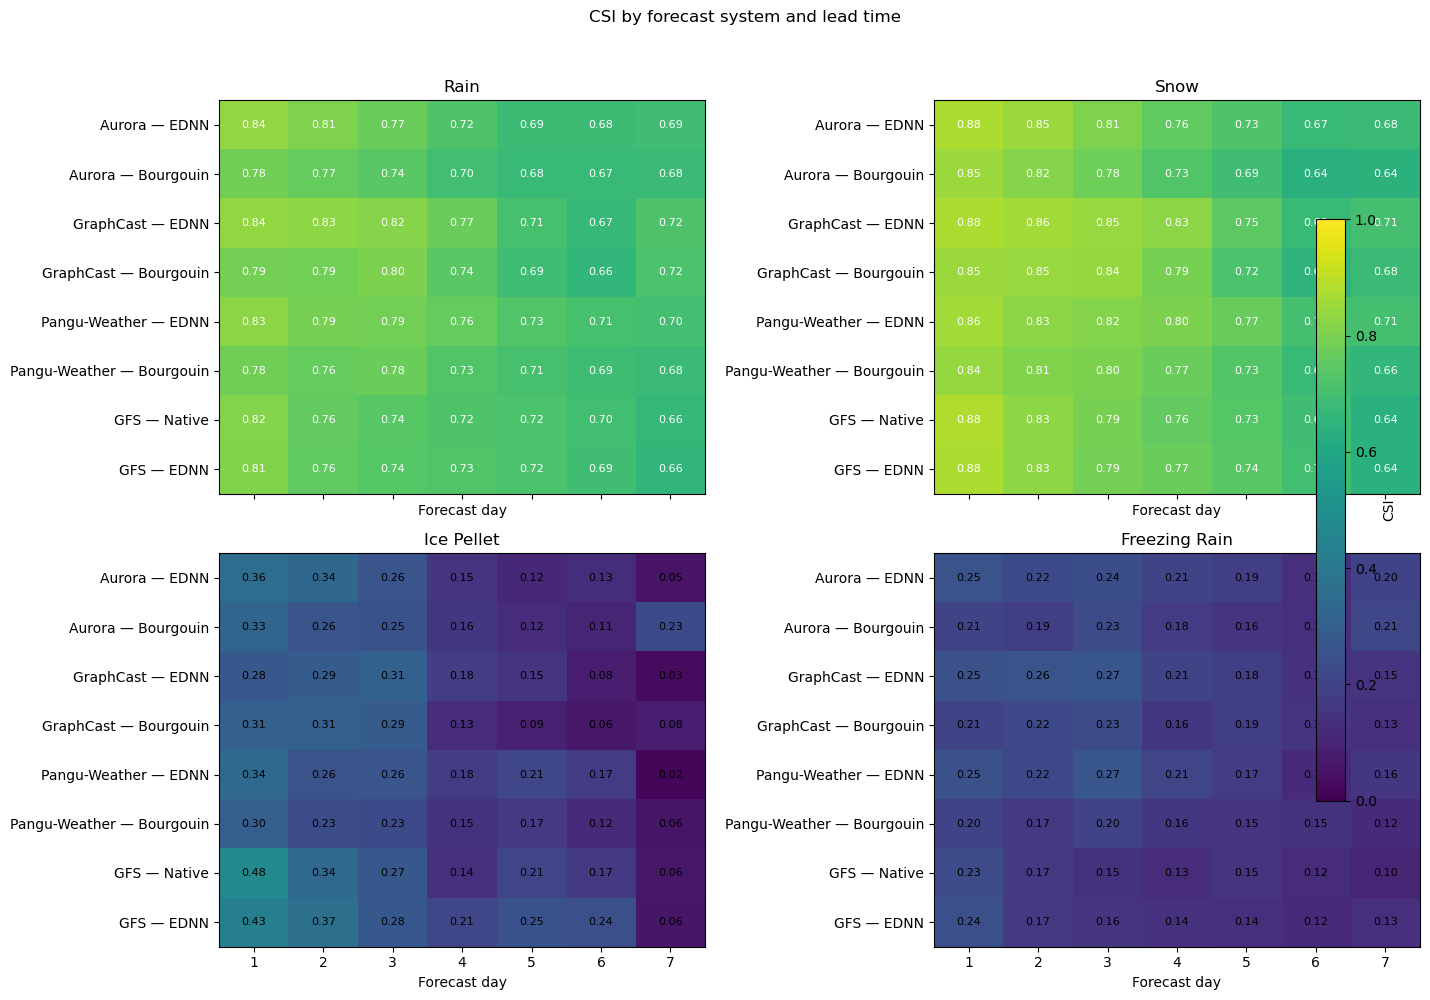

In [10]:
def metric_heatmaps(metric, cmap=None, vmin=None, vmax=None, fmt=".2f"):
    fig, axs = plt.subplots(2,2,figsize=(15,10), sharex=True)
    axs = axs.ravel()

    if vmin is None:
        vmin = skill[metric].min()
    if vmax is None:
        vmax = skill[metric].max()

    im = None
    for ax, ptype in zip(axs, CLASS_ORDER):
        z = (
            skill[skill.Class == ptype]
            .pivot(index="System", columns="Forecast_Day", values=metric)
            .reindex(SYSTEM_ORDER)
            .reindex(columns=range(1,8))
        )

        im = ax.imshow(z.values, aspect="auto", vmin=vmin, vmax=vmax, cmap=cmap)
        ax.set_title(ptype)
        ax.set_yticks(range(len(z.index)), z.index)
        ax.set_xticks(range(7), range(1,8))
        ax.set_xlabel("Forecast day")

        threshold = (vmin + vmax)/2
        for i in range(z.shape[0]):
            for j in range(z.shape[1]):
                val = z.iloc[i,j]
                if np.isfinite(val):
                    ax.text(j,i,format(val,fmt),ha="center",va="center",
                            color="white" if val > threshold else "black",fontsize=8)

    fig.suptitle(f"{metric} by forecast system and lead time", y=.995)
    fig.colorbar(im, ax=axs.tolist(), label=metric, fraction=.025, pad=.02)
    plt.tight_layout(rect=[0,0,.96,.97])
    plt.show()

metric_heatmaps("CSI", vmin=0, vmax=1)


### POD, FAR and frequency-bias diagnostic heatmaps


/glade/derecho/scratch/sakor/tmp/ipykernel_80459/403445344.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,.96,.97])


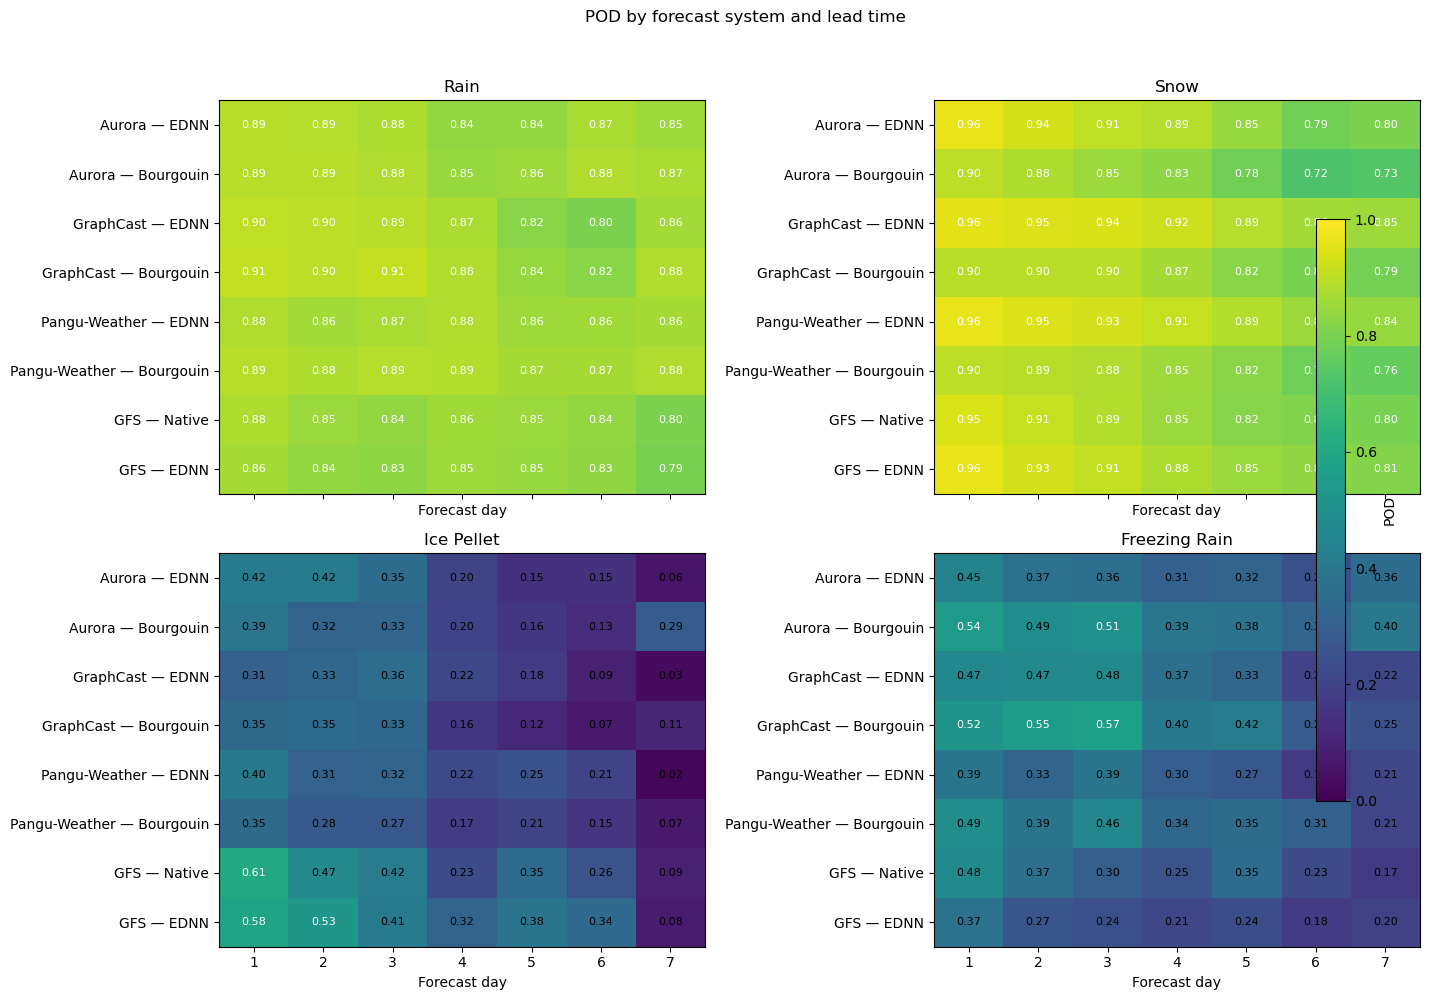

/glade/derecho/scratch/sakor/tmp/ipykernel_80459/403445344.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,.96,.97])


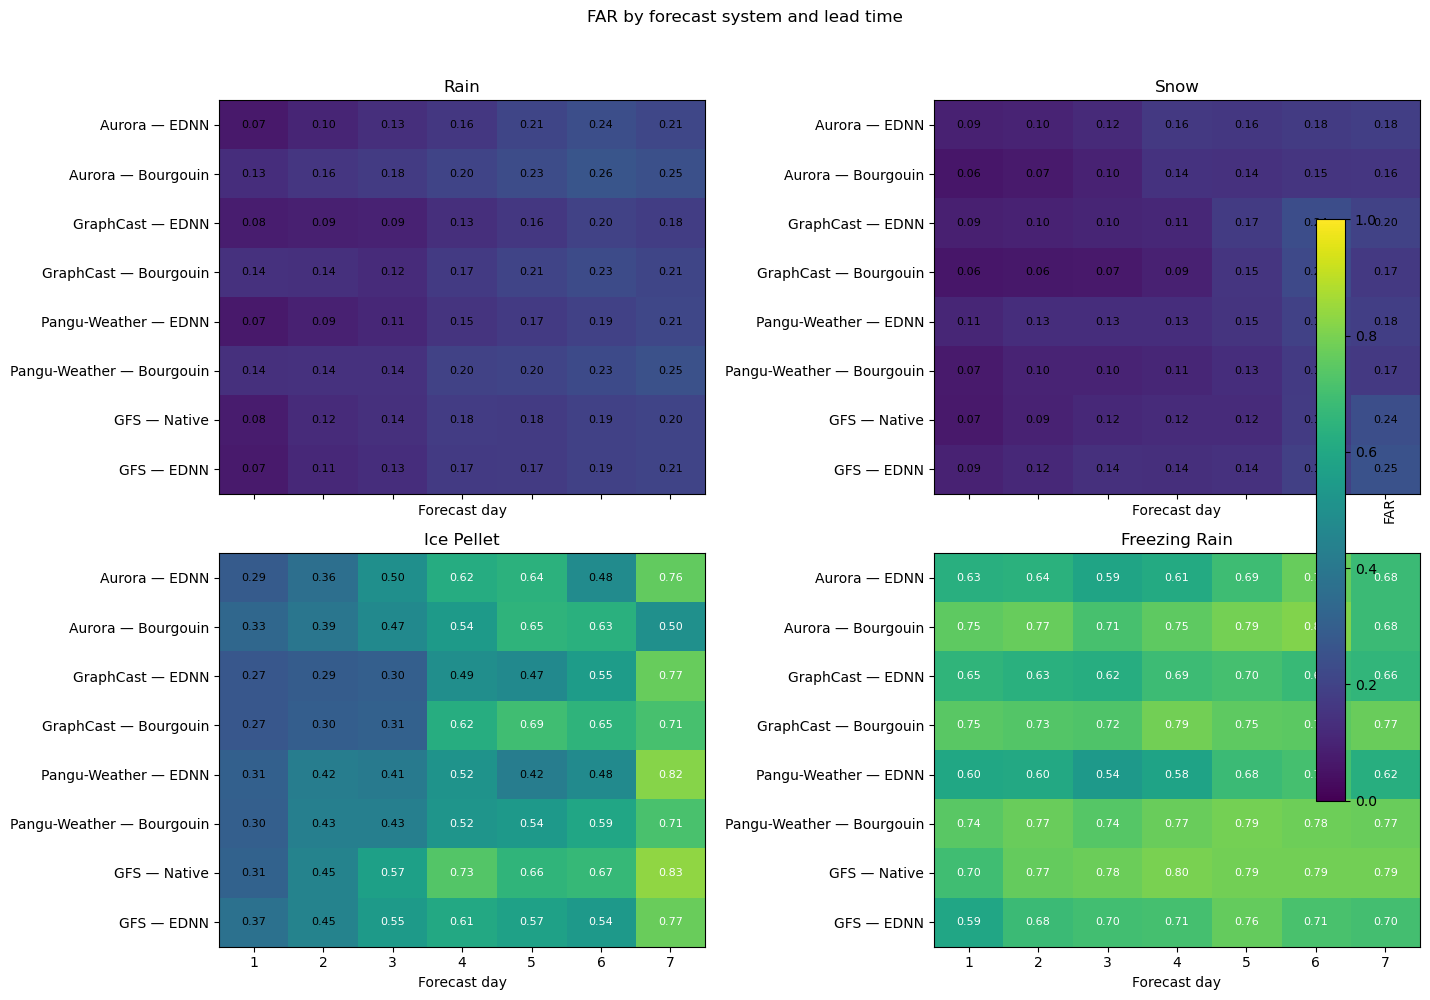

/glade/derecho/scratch/sakor/tmp/ipykernel_80459/403445344.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,.96,.97])


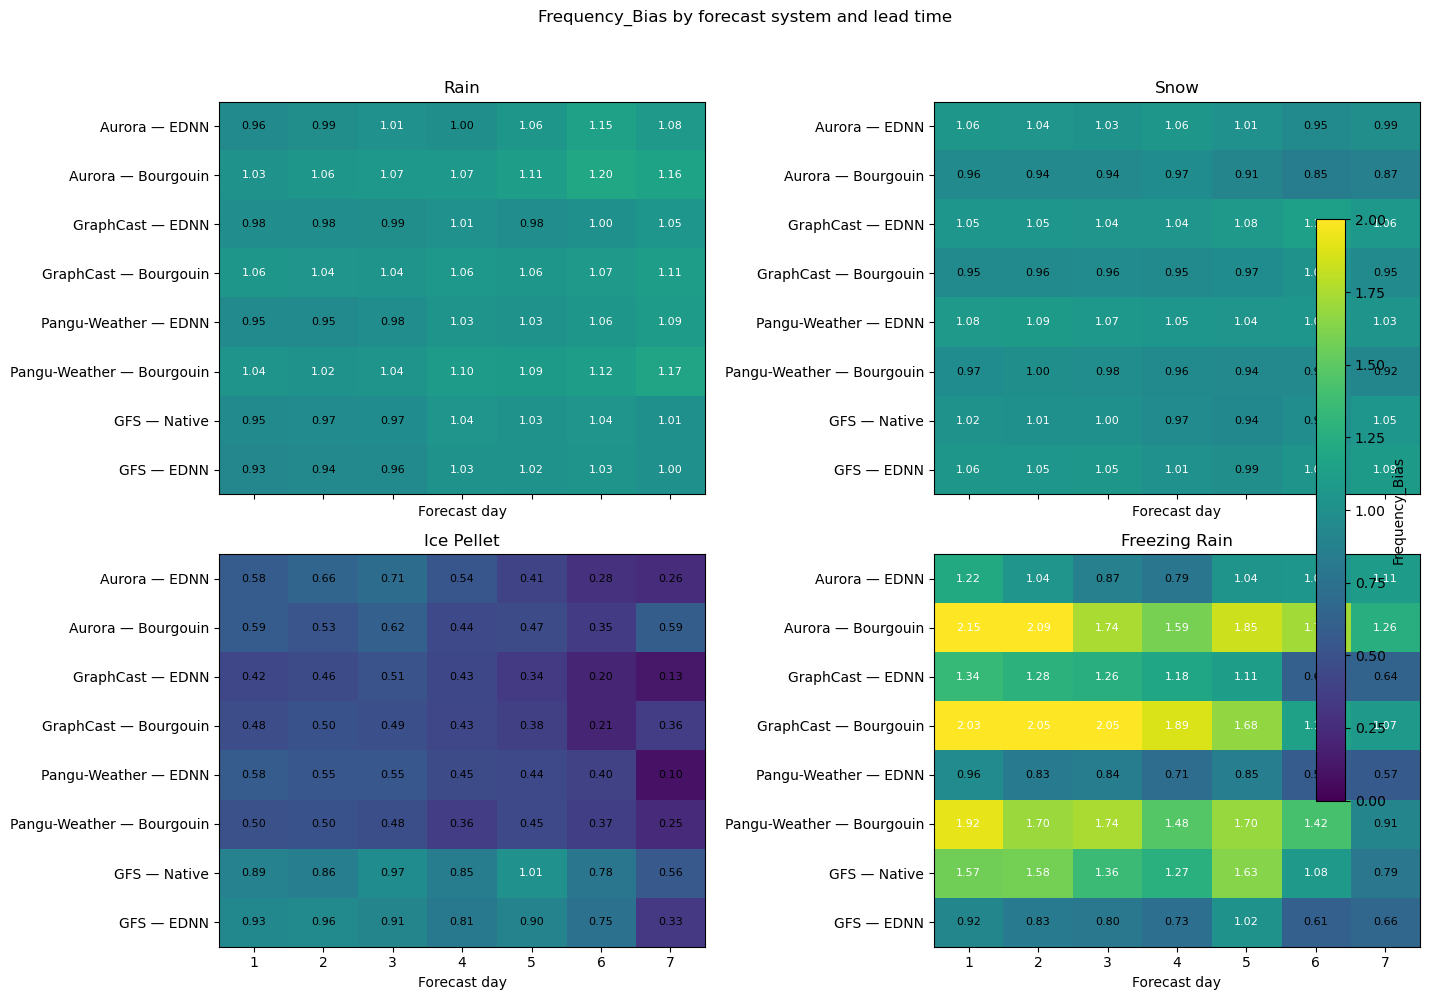

In [11]:
metric_heatmaps("POD", vmin=0, vmax=1)
metric_heatmaps("FAR", vmin=0, vmax=1)

# Bias is centered conceptually around 1; let data determine the upper limit.
metric_heatmaps("Frequency_Bias", vmin=0, vmax=max(2, skill.Frequency_Bias.quantile(.98)))


## 9. Rain/snow reassignment of observed Ice Pellet and Freezing Rain

For each system, calculate

\[
P(\hat y \in \{\mathrm{Rain,Snow}\}\mid y_{\mathrm{mPING}}=\mathrm{Ice\ Pellet})
\]

and

\[
P(\hat y \in \{\mathrm{Rain,Snow}\}\mid y_{\mathrm{mPING}}=\mathrm{Freezing\ Rain}).
\]

This avoids the ambiguous term *mixed phase*.


In [12]:
collapse_rows = []

for system in SYSTEM_ORDER:
    s = common[common.System == system]
    for obs_name in FRZR_IP_CLASSES:
        x = s[s.obs_class == obs_name]
        for day in range(1,8):
            d = x[x.forecast_day == day]
            rs = d.pred_code.isin([CLASS_CODES["Rain"], CLASS_CODES["Snow"]])
            collapse_rows.append({
                "System": system,
                "Observed": obs_name,
                "Forecast_Day": day,
                "N": len(d),
                "RainSnow_Fraction": rs.mean(),
            })

collapse = pd.DataFrame(collapse_rows)
collapse.to_csv(OUT/"frzr_ip_reassignment_to_rain_snow.csv", index=False)
display(collapse.head())


,System,Observed,Forecast_Day,N,RainSnow_Fraction
0,Aurora — EDNN,Ice Pellet,1,1018,0.371316
1,Aurora — EDNN,Ice Pellet,2,1004,0.402390
2,Aurora — EDNN,Ice Pellet,3,898,0.532294
3,Aurora — EDNN,Ice Pellet,4,862,0.679814
4,Aurora — EDNN,Ice Pellet,5,786,0.636132


### Rain/snow reassignment heatmaps


/glade/derecho/scratch/sakor/tmp/ipykernel_80459/1713030737.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,.95,.95])


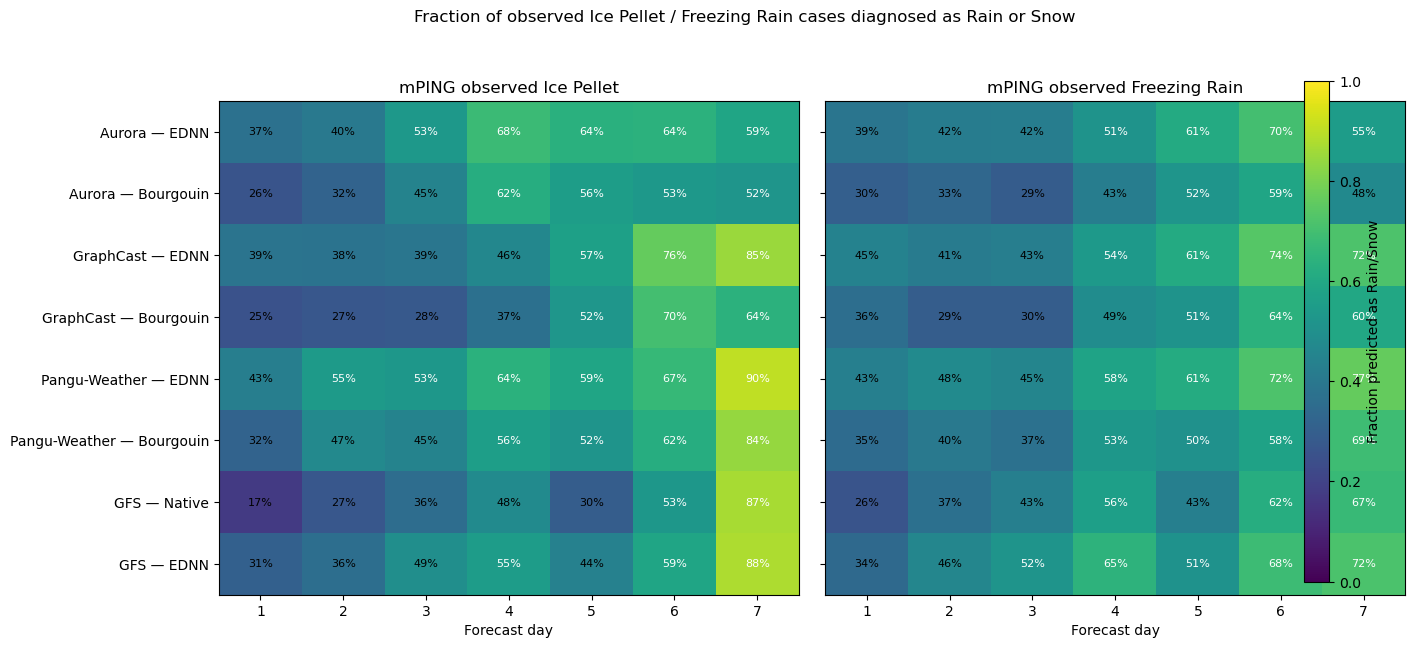

In [13]:
fig, axs = plt.subplots(1,2,figsize=(15,6.5), sharey=True)

for ax, obs_name in zip(axs, FRZR_IP_CLASSES):
    z = (
        collapse[collapse.Observed == obs_name]
        .pivot(index="System", columns="Forecast_Day", values="RainSnow_Fraction")
        .reindex(SYSTEM_ORDER)
        .reindex(columns=range(1,8))
    )

    im = ax.imshow(z.values, aspect="auto", vmin=0, vmax=1)
    ax.set_title(f"mPING observed {obs_name}")
    ax.set_xlabel("Forecast day")
    ax.set_xticks(range(7), range(1,8))
    ax.set_yticks(range(len(z.index)), z.index)

    for i in range(z.shape[0]):
        for j in range(z.shape[1]):
            val = z.iloc[i,j]
            if np.isfinite(val):
                ax.text(j,i,f"{100*val:.0f}%",ha="center",va="center",
                        color="white" if val > .5 else "black",fontsize=8)

fig.suptitle("Fraction of observed Ice Pellet / Freezing Rain cases diagnosed as Rain or Snow", y=.99)
fig.colorbar(im, ax=axs.tolist(), label="Fraction predicted as Rain/Snow", fraction=.035, pad=.03)
plt.tight_layout(rect=[0,0,.95,.95])
plt.savefig(FIG/"multimodel_frzr_ip_to_rain_snow_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. EDNN uncertainty dataset

Uncertainty is evaluated for the four EDNN applications only:

- Aurora
- GraphCast
- Pangu-Weather
- GFS

For each mPING-observed class:

\[
U_\mathrm{total}=U_\mathrm{aleatoric}+U_\mathrm{epistemic}.
\]

Unlike the eight-system skill comparison, the uncertainty comparison requires only the four EDNN datasets. We nevertheless restrict it to the same common `(obs_id, forecast_day)` keys used above so that uncertainty, reassignment and skill refer to the same observations.


In [14]:
unc_frames = []

for model in ["Aurora","GraphCast","Pangu-Weather","GFS"]:
    d = collocated[model].merge(common_keys, on=["obs_id","forecast_day"], how="inner").copy()
    d = d[d.spatial_match_valid & d.ML_ptype.isin(CLASS_NAMES)].copy()
    d["Model"] = model

    for ptype in CLASS_ORDER:
        d[f"{ptype}_epi"] = d[EPI_VARS[ptype]]
        d[f"{ptype}_ale"] = d[ALE_VARS[ptype]]
        d[f"{ptype}_total"] = d[EPI_VARS[ptype]] + d[ALE_VARS[ptype]]

    unc_frames.append(d)

unc = pd.concat(unc_frames, ignore_index=True)
print(unc.groupby("Model").size())


Model
Aurora           109746
GFS              109746
GraphCast        109746
Pangu-Weather    109746
dtype: int64


## 11. Total, epistemic and aleatoric uncertainty conditioned on mPING observation


In [15]:
unc_rows = []

for model in ["Aurora","GraphCast","Pangu-Weather","GFS"]:
    m = unc[unc.Model == model]
    for obs_name in FRZR_IP_CLASSES:
        x = m[m.obs_class == obs_name]
        for day in range(1,8):
            d = x[x.forecast_day == day]
            for component in ["total","epi","ale"]:
                q = d[f"{obs_name}_{component}"].dropna()
                unc_rows.append({
                    "Model": model, "Observed": obs_name, "Forecast_Day": day,
                    "Component": component, "N": len(q),
                    "Mean": q.mean(), "Median": q.median(),
                    "Q25": q.quantile(.25), "Q75": q.quantile(.75),
                })

unc_stats = pd.DataFrame(unc_rows)
unc_stats.to_csv(OUT/"ednn_uncertainty_by_observed_class.csv", index=False)
display(unc_stats.head())


,Model,Observed,Forecast_Day,Component,N,Mean,Median,Q25,Q75
0,Aurora,Ice Pellet,1,total,1018,0.151471,0.196366,0.045603,0.235570
1,Aurora,Ice Pellet,1,epi,1018,0.009494,0.012001,0.002075,0.014978
2,Aurora,Ice Pellet,1,ale,1018,0.141978,0.182923,0.043518,0.221092
3,Aurora,Ice Pellet,2,total,1004,0.144147,0.186249,0.030760,0.236139
4,Aurora,Ice Pellet,2,epi,1004,0.009278,0.011433,0.000947,0.015000


### Primary uncertainty figure: total predictive uncertainty


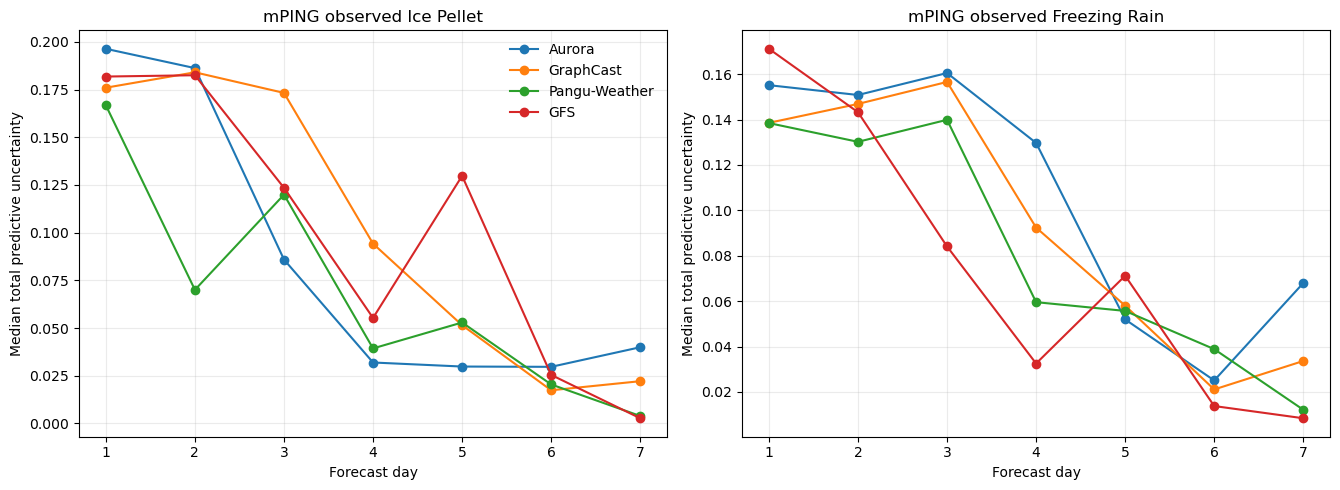

In [16]:
fig, axs = plt.subplots(1,2,figsize=(13.5,5), sharex=True)

for ax, obs_name in zip(axs, FRZR_IP_CLASSES):
    for model in ["Aurora","GraphCast","Pangu-Weather","GFS"]:
        x = unc_stats[
            (unc_stats.Model == model) &
            (unc_stats.Observed == obs_name) &
            (unc_stats.Component == "total")
        ].sort_values("Forecast_Day")

        ax.plot(x.Forecast_Day, x.Median, marker="o", label=model)

    ax.set_title(f"mPING observed {obs_name}")
    ax.set_xlabel("Forecast day")
    ax.set_ylabel("Median total predictive uncertainty")
    ax.set_xticks(range(1,8))
    ax.grid(alpha=.25)

axs[0].legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG/"multimodel_total_uncertainty.png", dpi=300, bbox_inches="tight")
plt.show()


### Uncertainty-component diagnostic

This is primarily diagnostic/supplementary. It reveals whether contraction in total uncertainty is dominated by the aleatoric component, epistemic component, or both.


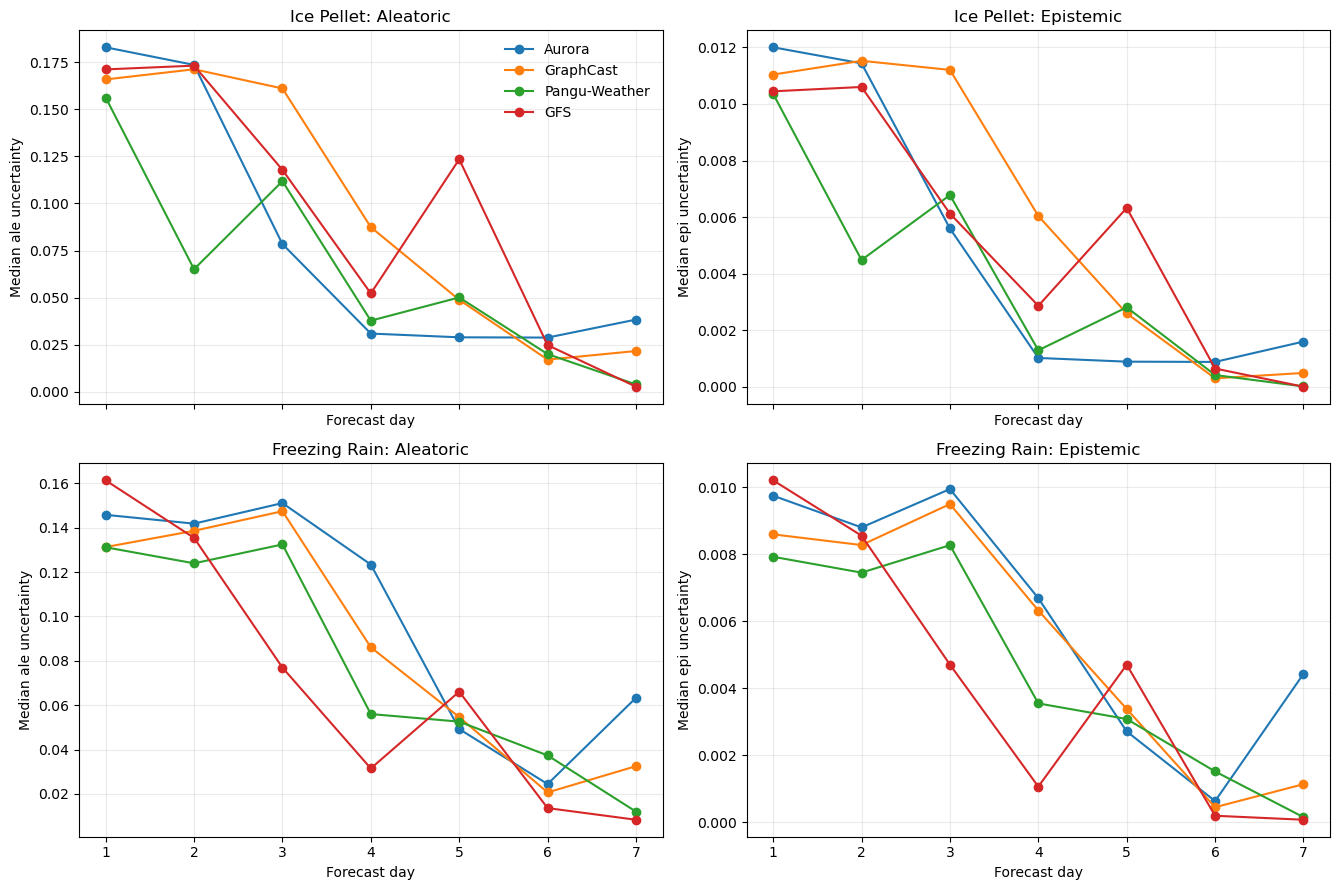

In [17]:
fig, axs = plt.subplots(2,2,figsize=(13.5,9), sharex=True)

for row, obs_name in enumerate(FRZR_IP_CLASSES):
    for col, component in enumerate(["ale","epi"]):
        ax = axs[row,col]
        for model in ["Aurora","GraphCast","Pangu-Weather","GFS"]:
            x = unc_stats[
                (unc_stats.Model == model) &
                (unc_stats.Observed == obs_name) &
                (unc_stats.Component == component)
            ].sort_values("Forecast_Day")
            ax.plot(x.Forecast_Day, x.Median, marker="o", label=model)

        title_component = "Aleatoric" if component == "ale" else "Epistemic"
        ax.set_title(f"{obs_name}: {title_component}")
        ax.set_xlabel("Forecast day")
        ax.set_ylabel(f"Median {component} uncertainty")
        ax.set_xticks(range(1,8))
        ax.grid(alpha=.25)

axs[0,0].legend(frameon=False)
plt.tight_layout()
plt.show()


## 12. EDNN reassignment versus total uncertainty

This connects the two phenomena quantitatively. Each point is one forecast day for one atmospheric forecast source.

The plot is descriptive: a relationship does not by itself prove the physical cause of the forecast-state change.


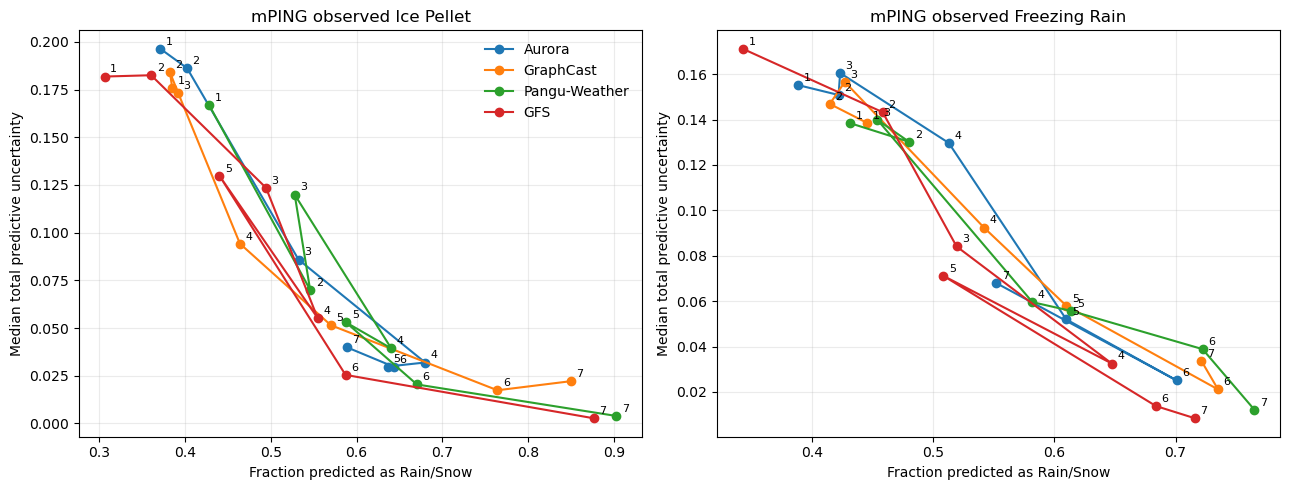

In [18]:
# EDNN-only collapse table
ednn_system = {
    "Aurora": "Aurora — EDNN",
    "GraphCast": "GraphCast — EDNN",
    "Pangu-Weather": "Pangu-Weather — EDNN",
    "GFS": "GFS — EDNN",
}

fig, axs = plt.subplots(1,2,figsize=(13,5))

for ax, obs_name in zip(axs, FRZR_IP_CLASSES):
    for model, system in ednn_system.items():
        c = collapse[(collapse.System == system) & (collapse.Observed == obs_name)][
            ["Forecast_Day","RainSnow_Fraction"]
        ]
        u = unc_stats[
            (unc_stats.Model == model) &
            (unc_stats.Observed == obs_name) &
            (unc_stats.Component == "total")
        ][["Forecast_Day","Median"]]

        z = c.merge(u, on="Forecast_Day").sort_values("Forecast_Day")
        ax.plot(z.RainSnow_Fraction, z.Median, marker="o", label=model)

        for r in z.itertuples():
            ax.annotate(str(r.Forecast_Day), (r.RainSnow_Fraction, r.Median),
                        xytext=(4,3), textcoords="offset points", fontsize=8)

    ax.set_title(f"mPING observed {obs_name}")
    ax.set_xlabel("Fraction predicted as Rain/Snow")
    ax.set_ylabel("Median total predictive uncertainty")
    ax.grid(alpha=.25)

axs[0].legend(frameon=False)
plt.tight_layout()
plt.show()


## 13. EDNN minus Bourgouin CSI within each AI-NWP

This diagnostic compares precipitation-type methods while holding the atmospheric forecast source fixed:

\[
\Delta CSI = CSI_\mathrm{EDNN}-CSI_\mathrm{Bourgouin}.
\]

Positive and negative values are simply differences; they should not be interpreted as an overall ranking of forecast systems.


/glade/derecho/scratch/sakor/tmp/ipykernel_80459/1106984810.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,.95,.95])


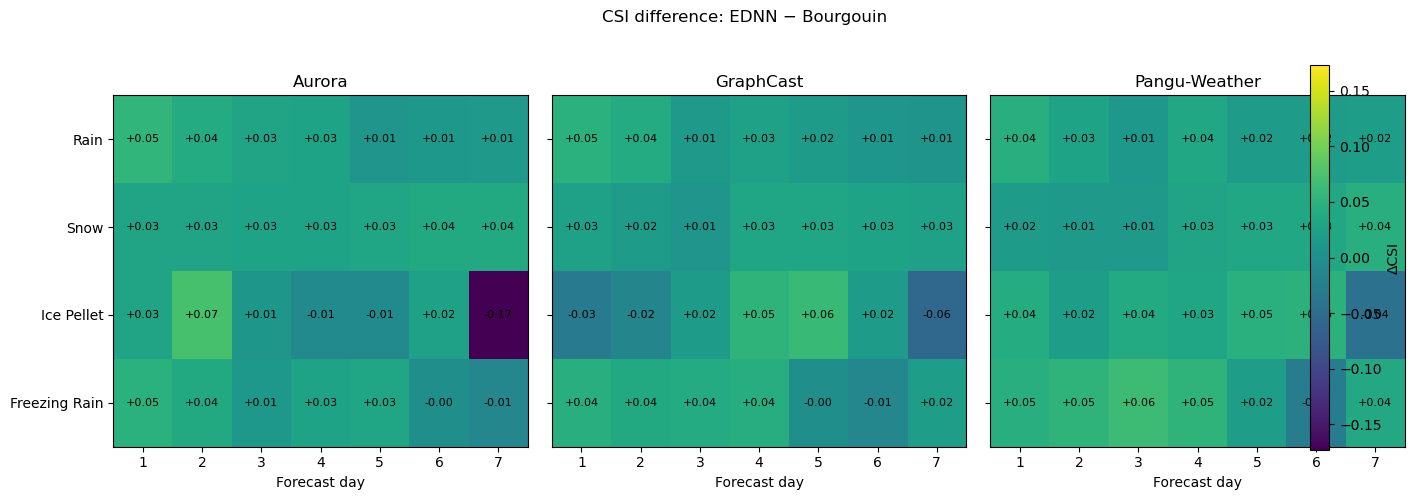

In [19]:
delta_rows = []

for model in ["Aurora","GraphCast","Pangu-Weather"]:
    for ptype in CLASS_ORDER:
        e = skill[(skill.System == f"{model} — EDNN") & (skill.Class == ptype)][
            ["Forecast_Day","CSI"]
        ].rename(columns={"CSI":"CSI_EDNN"})
        b = skill[(skill.System == f"{model} — Bourgouin") & (skill.Class == ptype)][
            ["Forecast_Day","CSI"]
        ].rename(columns={"CSI":"CSI_Bourgouin"})

        z = e.merge(b, on="Forecast_Day")
        z["Delta_CSI"] = z.CSI_EDNN - z.CSI_Bourgouin
        z["Model"] = model
        z["Class"] = ptype
        delta_rows.append(z)

delta = pd.concat(delta_rows, ignore_index=True)
delta.to_csv(OUT/"ednn_minus_bourgouin_csi.csv", index=False)

fig, axs = plt.subplots(1,3,figsize=(15,5), sharey=True)
lim = np.nanmax(np.abs(delta.Delta_CSI))

for ax, model in zip(axs, ["Aurora","GraphCast","Pangu-Weather"]):
    z = (
        delta[delta.Model == model]
        .pivot(index="Class", columns="Forecast_Day", values="Delta_CSI")
        .reindex(CLASS_ORDER)
        .reindex(columns=range(1,8))
    )
    im = ax.imshow(z.values, aspect="auto", vmin=-lim, vmax=lim)
    ax.set_title(model)
    ax.set_yticks(range(4), z.index)
    ax.set_xticks(range(7), range(1,8))
    ax.set_xlabel("Forecast day")

    for i in range(z.shape[0]):
        for j in range(z.shape[1]):
            val = z.iloc[i,j]
            ax.text(j,i,f"{val:+.2f}",ha="center",va="center",fontsize=8)

fig.suptitle("CSI difference: EDNN − Bourgouin", y=.99)
fig.colorbar(im, ax=axs.tolist(), label="ΔCSI", fraction=.03, pad=.03)
plt.tight_layout(rect=[0,0,.95,.95])
plt.show()


## 14. Day-1 to Day-7 summary tables


In [20]:
# Skill changes
skill_change = (
    skill[skill.Forecast_Day.isin([1,7])]
    .pivot_table(index=["System","Class"], columns="Forecast_Day", values=["CSI","POD","FAR","Frequency_Bias"])
)
skill_change.columns = [f"{m}_D{d}" for m,d in skill_change.columns]
skill_change = skill_change.reset_index()

for m in ["CSI","POD","FAR","Frequency_Bias"]:
    skill_change[f"{m}_change"] = skill_change[f"{m}_D7"] - skill_change[f"{m}_D1"]

# Reassignment changes
collapse_change = (
    collapse[collapse.Forecast_Day.isin([1,7])]
    .pivot(index=["System","Observed"], columns="Forecast_Day", values="RainSnow_Fraction")
    .rename(columns={1:"D1",7:"D7"}).reset_index()
)
collapse_change["Change"] = collapse_change.D7 - collapse_change.D1

# Total uncertainty changes
total_change = (
    unc_stats[
        (unc_stats.Component == "total") &
        unc_stats.Forecast_Day.isin([1,7])
    ]
    .pivot(index=["Model","Observed"], columns="Forecast_Day", values="Median")
    .rename(columns={1:"D1",7:"D7"}).reset_index()
)
total_change["Absolute_change"] = total_change.D7 - total_change.D1
total_change["Percent_change"] = (total_change.D7/total_change.D1 - 1)*100

display(skill_change.round(3))
display(collapse_change.round(3))
display(total_change.round(3))

skill_change.to_csv(OUT/"day1_day7_skill_changes.csv", index=False)
collapse_change.to_csv(OUT/"day1_day7_rainsnow_reassignment_changes.csv", index=False)
total_change.to_csv(OUT/"day1_day7_total_uncertainty_changes.csv", index=False)


,System,Class,CSI_D1,CSI_D7,FAR_D1,FAR_D7,Frequency_Bias_D1,Frequency_Bias_D7,POD_D1,POD_D7,CSI_change,POD_change,FAR_change,Frequency_Bias_change
0,Aurora — Bourgouin,Freezing Rain,0.206,0.215,0.750,0.683,2.148,1.257,0.537,0.399,0.009,-0.138,-0.067,-0.892
1,Aurora — Bourgouin,Ice Pellet,0.327,0.225,0.332,0.504,0.585,0.588,0.391,0.292,-0.102,-0.099,0.172,0.003
2,Aurora — Bourgouin,Rain,0.785,0.681,0.132,0.246,1.028,1.159,0.892,0.875,-0.104,-0.017,0.113,0.132
3,Aurora — Bourgouin,Snow,0.849,0.643,0.062,0.158,0.959,0.869,0.899,0.732,-0.206,-0.168,0.097,-0.089
4,Aurora — EDNN,Freezing Rain,0.254,0.202,0.631,0.680,1.216,1.109,0.449,0.355,-0.052,-0.094,0.049,-0.106
5,Aurora — EDNN,Ice Pellet,0.357,0.052,0.286,0.759,0.583,0.257,0.417,0.062,-0.305,-0.355,0.472,-0.327
6,Aurora — EDNN,Rain,0.840,0.694,0.067,0.212,0.957,1.083,0.893,0.854,-0.145,-0.039,0.145,0.126
7,Aurora — EDNN,Snow,0.878,0.681,0.091,0.184,1.059,0.985,0.963,0.804,-0.197,-0.159,0.093,-0.074
8,GFS — EDNN,Freezing Rain,0.243,0.134,0.591,0.702,0.915,0.661,0.375,0.197,-0.109,-0.178,0.112,-0.254
9,GFS — EDNN,Ice Pellet,0.432,0.060,0.375,0.773,0.933,0.332,0.583,0.075,-0.372,-0.508,0.399,-0.601


Forecast_Day,System,Observed,D1,D7,Change
0,Aurora — Bourgouin,Freezing Rain,0.304,0.475,0.172
1,Aurora — Bourgouin,Ice Pellet,0.261,0.522,0.261
2,Aurora — EDNN,Freezing Rain,0.389,0.552,0.163
3,Aurora — EDNN,Ice Pellet,0.371,0.588,0.217
4,GFS — EDNN,Freezing Rain,0.343,0.716,0.373
5,GFS — EDNN,Ice Pellet,0.306,0.876,0.570
6,GFS — Native,Freezing Rain,0.261,0.672,0.411
7,GFS — Native,Ice Pellet,0.169,0.867,0.698
8,GraphCast — Bourgouin,Freezing Rain,0.360,0.601,0.241
9,GraphCast — Bourgouin,Ice Pellet,0.253,0.642,0.388


Forecast_Day,Model,Observed,D1,D7,Absolute_change,Percent_change
0,Aurora,Freezing Rain,0.155,0.068,-0.087,-56.193001
1,Aurora,Ice Pellet,0.196,0.040,-0.156,-79.648003
2,GFS,Freezing Rain,0.171,0.008,-0.163,-95.094002
3,GFS,Ice Pellet,0.182,0.003,-0.179,-98.487000
4,GraphCast,Freezing Rain,0.139,0.034,-0.105,-75.733002
5,GraphCast,Ice Pellet,0.176,0.022,-0.154,-87.401001
6,Pangu-Weather,Freezing Rain,0.138,0.012,-0.126,-91.231003
7,Pangu-Weather,Ice Pellet,0.167,0.004,-0.163,-97.634003


## 15. Interpretation checklist

Before drawing conclusions, check these jointly:

- Does CSI decline with lead time for Ice Pellet and Freezing Rain?
- Does the fraction of those mPING-observed cases diagnosed as Rain/Snow increase?
- Is the increase present in **both EDNN and Bourgouin** for the same AI-NWP?
- Does native GFS show a similar or different lead-time behavior?
- Does total EDNN predictive uncertainty decrease for those same observed cases?
- Do both aleatoric and epistemic components contract, or is one dominant?
- Are conclusions robust on the identical common-valid sample?

If EDNN and Bourgouin show similar reassignment for the same atmospheric forecast, that is consistent with degradation/change in the forecast thermodynamic state contributing to the behavior. It does **not by itself prove** the meteorological mechanism; demonstrating that would require analysis of the forecast temperature/moisture profiles.
